# Country-Wise Netflix Content Analysis

## Objective
This analysis explores the geographical distribution of Netflix content by identifying the countries contributing the highest number of titles to the platform.

The analysis includes country-wise content distribution, top content-producing countries, visualizations, and business insights.

## Dataset
The cleaned Netflix dataset is used as the input for this analysis.

In [13]:
import pandas as pd
import matplotlib.pyplot as plt

In [14]:
df = pd.read_csv("Netflix_Cleaned_Dataset.csv")

print("Dataset Shape:", df.shape)

df.head()

Dataset Shape: (8790, 10)


,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,9/25/2021,2020,PG-13,90 min,Documentaries
1,s3,TV Show,Ganglands,Julien Leclercq,France,9/24/2021,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act..."
2,s6,TV Show,Midnight Mass,Mike Flanagan,United States,9/24/2021,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries"
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,9/22/2021,2021,TV-PG,91 min,"Children & Family Movies, Comedies"
4,s8,Movie,Sankofa,Haile Gerima,United States,9/24/2021,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies"


In [15]:
print("Country Column Information:")
print(df['country'].info())

print("\nMissing Country Values:")
print(df['country'].isnull().sum())

print("\nSample Country Values:")
print(df['country'].dropna().head(10).tolist())

Country Column Information:
<class 'pandas.core.series.Series'>
RangeIndex: 8790 entries, 0 to 8789
Series name: country
Non-Null Count  Dtype 
--------------  ----- 
8503 non-null   object
dtypes: object(1)
memory usage: 68.8+ KB
None

Missing Country Values:
287

Sample Country Values:
['United States', 'France', 'United States', 'Brazil', 'United States', 'United Kingdom', 'United States', 'India', 'Germany', 'India']


In [16]:
# Select records with available country information
country_df = df[['show_id', 'title', 'type', 'country']].dropna(subset=['country']).copy()

# Split multiple countries into separate rows
country_df['country'] = country_df['country'].str.split(',')

# Expand each country into an individual row
country_df = country_df.explode('country')

# Remove extra spaces
country_df['country'] = country_df['country'].str.strip()

# Remove empty country entries
country_df = country_df[country_df['country'] != '']

print("Country-Level Dataset Shape:", country_df.shape)

country_df.head(10)

Country-Level Dataset Shape: (8503, 4)


,show_id,title,type,country
0,s1,Dick Johnson Is Dead,Movie,United States
1,s3,Ganglands,TV Show,France
2,s6,Midnight Mass,TV Show,United States
3,s14,Confessions of an Invisible Girl,Movie,Brazil
4,s8,Sankofa,Movie,United States
5,s9,The Great British Baking Show,TV Show,United Kingdom
6,s10,The Starling,Movie,United States
7,s939,Motu Patlu in the Game of Zones,Movie,India
8,s13,Je Suis Karl,Movie,Germany
9,s940,Motu Patlu in Wonderland,Movie,India


In [17]:
print("Total Country Entries:", len(country_df))

print("Unique Countries:", country_df['country'].nunique())

print("\nTop 10 Country Names:")
print(country_df['country'].value_counts().head(10))

Total Country Entries: 8503
Unique Countries: 85

Top 10 Country Names:
country
United States     3240
India             1057
United Kingdom     638
Pakistan           421
Canada             271
Japan              259
South Korea        214
France             213
Spain              182
Mexico             138
Name: count, dtype: int64


In [18]:
print("Missing Country Values:", country_df['country'].isnull().sum())

print("Duplicate Country-Title Combinations:",
      country_df.duplicated(subset=['show_id', 'country']).sum())

print("\nSample Extracted Records:")
country_df.sample(10, random_state=42)

Missing Country Values: 0
Duplicate Country-Title Combinations: 0

Sample Extracted Records:


,show_id,title,type,country
1239,s1320,Xico's Journey,Movie,Mexico
8702,s8232,The Bund,Movie,Hong Kong
6681,s526,My Little Pony: Friendship Is Magic,TV Show,United States
2703,s3561,Drink Drank Drunk,Movie,Hong Kong
4033,s5626,IBOY,Movie,United Kingdom
5476,s7491,"Monster High: Boo York, Boo York",Movie,United States
4844,s6690,Emo the Musical,Movie,Australia
2787,s3720,Bolívar,TV Show,Colombia
2456,s3139,Holy Expectations,Movie,Colombia
1458,s1655,Before 30,TV Show,Nigeria


In [19]:
country_counts = (
    country_df.groupby('country')['show_id']
    .nunique()
    .sort_values(ascending=False)
    .reset_index()
)

country_counts.columns = ['Country', 'Total Titles']

country_counts.head(10)

,Country,Total Titles
0,United States,3240
1,India,1057
2,United Kingdom,638
3,Pakistan,421
4,Canada,271
5,Japan,259
6,South Korea,214
7,France,213
8,Spain,182
9,Mexico,138


In [20]:
top_10_countries = country_counts.head(10)

print("Top 10 Countries by Netflix Content:\n")
print(top_10_countries.to_string(index=False))

Top 10 Countries by Netflix Content:

       Country  Total Titles
 United States          3240
         India          1057
United Kingdom           638
      Pakistan           421
        Canada           271
         Japan           259
   South Korea           214
        France           213
         Spain           182
        Mexico           138


In [21]:
total_country_titles = country_counts['Total Titles'].sum()

country_counts['Percentage'] = (
    country_counts['Total Titles'] / total_country_titles
) * 100

top_10_countries = country_counts.head(10).copy()

top_10_countries

,Country,Total Titles,Percentage
0,United States,3240,38.104199
1,India,1057,12.430907
2,United Kingdom,638,7.503234
3,Pakistan,421,4.951194
4,Canada,271,3.187110
5,Japan,259,3.045984
6,South Korea,214,2.516759
7,France,213,2.504998
8,Spain,182,2.140421
9,Mexico,138,1.622957


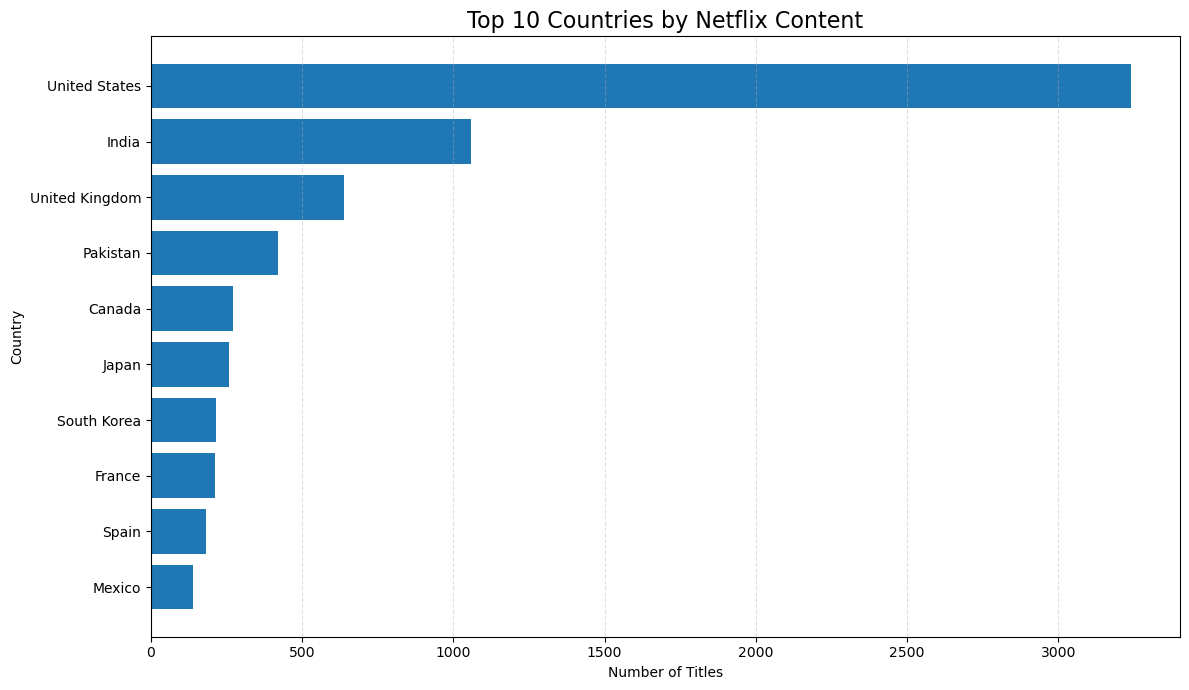

In [22]:
plt.figure(figsize=(12, 7))

plt.barh(
    top_10_countries['Country'][::-1],
    top_10_countries['Total Titles'][::-1]
)

plt.title('Top 10 Countries by Netflix Content', fontsize=16)
plt.xlabel('Number of Titles')
plt.ylabel('Country')

plt.grid(axis='x', linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

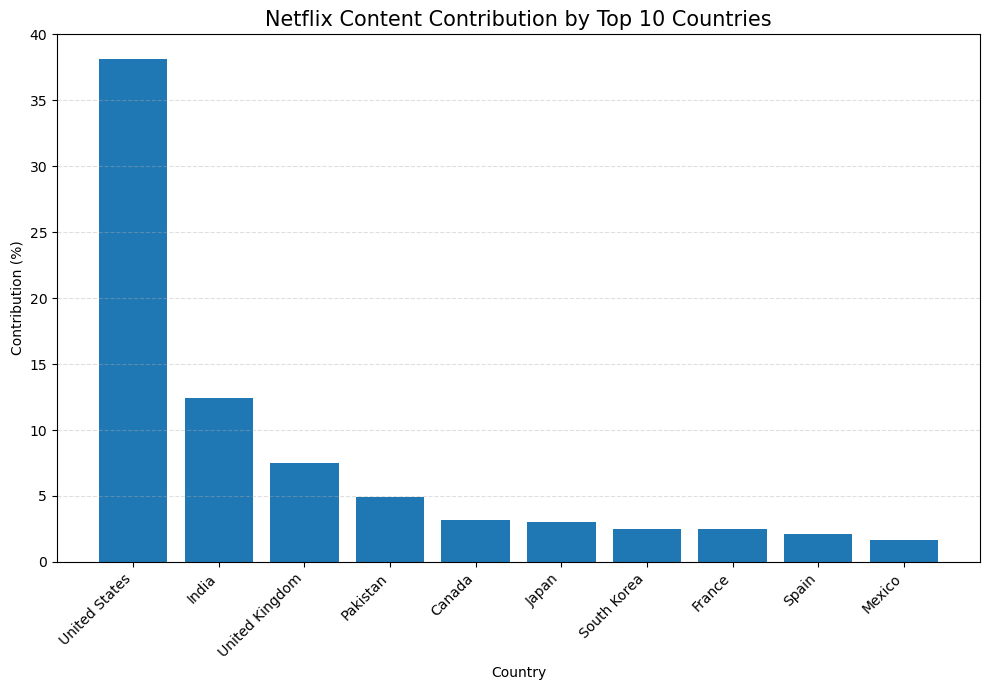

In [23]:
plt.figure(figsize=(10, 7))

plt.bar(
    top_10_countries['Country'],
    top_10_countries['Percentage']
)

plt.title('Netflix Content Contribution by Top 10 Countries', fontsize=15)
plt.xlabel('Country')
plt.ylabel('Contribution (%)')

plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

## Key Business Insights

1. The United States contributes the highest number of Netflix titles, with 3,240 country-title associations, representing approximately 38.10% of all country-title associations.

2. India ranks second with 1,057 titles, indicating a substantial contribution to Netflix's international content library.

3. The United Kingdom ranks third with 638 titles, showing its significant presence in the platform's content distribution.

4. Asian markets such as India, Pakistan, Japan, and South Korea appear among the top 10 countries, highlighting the geographical diversity of Netflix content.

5. The top three countries account for approximately 58.04% of all country-title associations, indicating a concentration of content among the leading contributors.



## Final Conclusion

The country-wise analysis identifies the United States as the largest contributor to Netflix's content library, followed by India and the United Kingdom.

The results highlight the geographical distribution of Netflix titles and show the importance of international content contributions. The findings can help understand content concentration across countries and identify markets with strong representation.

**Key Finding:** The top three countries account for approximately 58.04% of all country-title associations.